# Практическое задание 2. Диффузионные модели


## Оценивание и штрафы
Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи).

Сдавать задание после указанного жёсткого срока сдачи нельзя.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов. Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

## Формат сдачи !!ВАЖНО!!!
Задания сдаются через систему google classroom. Посылка должна содержать:
* Ноутбук ddpm_hw_bmmo-Username.ipynb

Username &ndash; ваша фамилия и имя на латинице именно в таком порядке

<p style="color:#de3815;font-size:25px;">
Напоминание об оформлении и выполнении ноутбука
</p>

* Все строчки должны быть выполнены. Нужно, чтобы output команды можно было увидеть, не запуская ячейки (кроме редких случаев, когда необходимо намеренно скрыть ненужный output, про такие случаи желательно писать пояснения в тексте). **В противном случае -1 балл**
* При оформлении ДЗ нужно пользоваться данным файлом в качестве шаблона. Не нужно удалять и видоизменять написанный код и текст, если явно не указана такая возможность. **В противном случае -1 балл**
* В anytask обязательно нужно прикреплять отдельно файл с расширением ipynb (не в архиве, а именно отдельно). Если необходимо отправить еще какие-то файлы, то вынесите их в отдельный архив (если файлов много) и пришлите. **В противном случае -0.5 балла*

# В этом задании необходимо будет дореализовать ключевые формулы для обучения дискретной диффузионной модели из статьи DDPM.

[Статья DDPM](https://arxiv.org/pdf/2006.11239.pdf)


---
Для выполнения домашнего задания достаточно использовать Google Colab.

## Описание эксперимента

Я обучил DDPM создавать рукописные цифры MNIST. Во время обучения к изображению добавляется шум, а сеть учится его предсказывать. При генерации модель начинает со случайного шума и постепенно получает изображение цифры. Номер нужной цифры модели не задаётся.

| Параметр | Значение |
| --- | --- |
| Данные | Обучающая выборка MNIST |
| Изображения | 1 × 32 × 32; значения от −1 до 1 |
| Сеть | U-Net: dim=64, dim_mults=(1, 2, 4, 4), channels=1 |
| Диффузия | 1000 шагов; β линейно растёт от 0,0001 до 0,02 |
| Обучение | 5000 шагов; батч — 128 изображений |
| Оптимизатор | AdamW; скорость обучения — 0,0002; weight decay — 0,01 |
| Функция потерь | MSE между добавленным и предсказанным шумом |
| Веса для генерации | EMA с коэффициентом 0,999 |
| Seed | 42 |
| Оценка качества | 5000 реальных и 5000 сгенерированных изображений |

EMA — сглаженные веса сети, которые обновляются во время обучения. Они использованы и для сетки цифр, и для генерации изображений для FID.

**Результаты этого запуска:** последний MSE — **0,02314**, средний MSE за последние 100 шагов — **0,01689**, FID на 5000 изображениях — **4,638421**. Ниже сохранены таблицы, графики и сетка из 100 генераций.

[Запуск W&B](https://wandb.ai/aashutov05-higher-school-of-economics/discrete_time_ddpm/runs/gxi9w0s0) · [Проект W&B](https://wandb.ai/aashutov05-higher-school-of-economics/discrete_time_ddpm)


In [1]:
!python3 -V
import torch


print(f'torch.__version__: {torch.__version__}')

Python 3.13.15
torch.__version__: 2.11.0+cu130


In [2]:
!pip3 install wandb comet_ml==3.55.0 -q     #установка логгеров
!pip3 install torch_ema denoising_diffusion_pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 780.9/780.9 kB 44.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 94.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.4/90.4 kB 9.9 MB/s eta 0:00:00


В задании по умолчанию выбран логгер wandb, вы можете, также использовать логгер comet_ml. В Anytask помимо ноутбука **надо будет сдать ссылку на публичный проект** в одном из этих логгеров.

In [3]:
import torch
import numpy as np
import random


def set_global_seed(seed: int) -> None:
    """
    Set global seed for reproducibility.
    """

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    random.seed(seed)
    np.random.seed(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_global_seed(42)

In [4]:
import platform
from IPython.display import display, Markdown

torch.set_num_threads(min(torch.get_num_threads(), 4))
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Устройство:", device)
print("CUDA доступна:", torch.cuda.is_available())
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(device))
else:
    raise RuntimeError("Для полного запуска выберите GPU в настройках среды Colab.")


Python: 3.13.15
PyTorch: 2.11.0+cu130
Устройство: cuda:0
CUDA доступна: True
GPU: NVIDIA A100-SXM4-40GB


In [5]:
from pathlib import Path
from datetime import datetime


def prepare_empty_image_folder(folder):
    path = Path(folder)
    if path.exists() and any(path.iterdir()):
        stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
        backup = path.with_name(f"{path.name}_previous_{stamp}")
        path.rename(backup)
        print(f"Предыдущие изображения сохранены: {backup}")


# Датасет

In [6]:
import os
import numpy as np
import PIL

from tqdm import tqdm
from torchvision.datasets import MNIST
from torch.utils.data import DataLoader, Dataset
from typing import Generator, Tuple, Dict, Optional, Union
from torch import Tensor
from cv2 import resize


def preprocess_image(image: "PIL.Image") -> np.ndarray:
    image = np.array(image, dtype=np.uint8)
    image = resize(image, (32, 32))
    return np.array(image, dtype=np.float32) / 127.5 - 1


def postprocess_image(image: torch.Tensor) -> torch.Tensor:
    # convert values to [0; 255]
    image = image.cpu().detach()
    image = (image + 1) * 127.5
    image = torch.clip(image, 0, 255)
    return image


class MnistDataset(Dataset):
    def __init__(self, train: bool = True):
        super().__init__()
        self.mnist = MNIST(
            'data',
            train=train,
            download=True
        )

    def __len__(self) -> int:
        return len(self.mnist)

    def __getitem__(self, index: int) -> Dict[str, Tensor]:
        image, target = self.mnist[index]
        image = preprocess_image(image)
        target = int(target)
        return {
            "images": Tensor(image)[None],
            "targets": target
        }

In [7]:
def dict_to_device(dct: Dict[str, Tensor], device: torch.device) -> Dict[str, Tensor]:
    return {k: v.to(device) for k, v in dct.items()}


def get_train_images_generator(
    batch_size: int = 128,
    num_workers: int = 0,
    shuffle: bool = True,
    drop_last: bool = True
) -> Generator[Dict[str, Tensor], None, None]:
    dataset = MnistDataset(train=True)
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        num_workers=num_workers,
        shuffle=shuffle,
        drop_last=drop_last
    )
    while True:
        yield from loader

In [8]:
def check_generator(batch_size: int = 128):
    generator = get_train_images_generator(batch_size)
    batch_dict = next(generator)
    assert(batch_dict['images'].shape == (batch_size, 1, 32, 32), batch_dict['images'].shape)
    assert(batch_dict['targets'].shape == (batch_size,), batch_dict['targets'].shape)

check_generator(131)

<>:4: SyntaxWarning: assertion is always true, perhaps remove parentheses?
<>:5: SyntaxWarning: assertion is always true, perhaps remove parentheses?
<>:4: SyntaxWarning: assertion is always true, perhaps remove parentheses?
<>:5: SyntaxWarning: assertion is always true, perhaps remove parentheses?
/tmp/ipykernel_1715/2113533935.py:4: SyntaxWarning: assertion is always true, perhaps remove parentheses?
  assert(batch_dict['images'].shape == (batch_size, 1, 32, 32), batch_dict['images'].shape)
/tmp/ipykernel_1715/2113533935.py:5: SyntaxWarning: assertion is always true, perhaps remove parentheses?
  assert(batch_dict['targets'].shape == (batch_size,), batch_dict['targets'].shape)
100%|██████████| 9.91M/9.91M [00:01<00:00, 4.96MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 129kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.22MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.4MB/s]


In [9]:
batch_check = next(get_train_images_generator(131))
assert batch_check["images"].shape == (131, 1, 32, 32)
assert batch_check["targets"].shape == (131,)
assert torch.isfinite(batch_check["images"]).all()
print("Форма и значения батча MNIST: OK")


Форма и значения батча MNIST: OK


# DDPM's dynamic (5 баллов)



В `get_coeffs_primities` (2 pts) необходимо в возвращаеый словарь добавить рассчет коэффицентов, при помощи которых вы сможете реализовать семплирование из распределений $q(x_t | x_0), q(x_t | x_{t+1}, x_0), p(x_t | x_{t + 1})$.

Например:
- $\alpha_t = 1 - \beta_t$
- $\bar{\alpha_t} = \prod_{t=1}^{T} \alpha_t$
- $\sqrt{\bar{\alpha_t}}$
- ...
- любые коэффиценты, которые помогут вам рассчитать коэффиценты в $q(x_t | x_0), q(x_t | x_{t+1}, x_0), p(x_t | x_{t + 1})$

`extract_values_from_times` - по батчу с целочислненными временами выдает батч коэфиицентов в нужном шейпе для перемножения с батчом картинок


### Прямой и обратный процессы

В прямом процессе к чистому изображению добавляется случайный шум. Чем дальше шаг, тем меньше видна исходная цифра. Формула позволяет сразу получить изображение на нужном шаге.

В коде `x_0` — чистое изображение, `x_t` — зашумлённое, `eps` — добавленный шум. Индексы идут от 0 до 999: индекс 0 обозначает первый шаг добавления шума.

Метод `sample_from_posterior_q` делает один шаг назад, когда чистое изображение известно. При генерации оно неизвестно, поэтому сеть предсказывает шум. Метод `single_step` использует это предсказание, чтобы получить менее зашумлённое изображение.

Генерация проходит все 1000 шагов в обратном порядке. На последнем шаге дополнительный шум не добавляется, потому что его коэффициент равен нулю.


In [10]:
from torch import nn


def get_coeffs_primitives(
    T: int = 1000,
    beta_min: float = 1e-4,
    beta_max: float = 2e-2,
) -> Dict[str, Tensor]:
    """
    output: Dict[str, Tensor]
      {
        "a": b
      }
    ---
    b.shape == (T,)
    """
    betas = torch.linspace(beta_min, beta_max, T).float()
    alphas = 1 - betas

    sqrt_alphas = torch.sqrt(alphas)
    alphas_hat = torch.cumprod(alphas, dim=0)

    alphas_hat_prev = torch.cat([torch.FloatTensor([1.]), alphas_hat[:-1]])

    # YOUR CODE GOES HERE

    sqrt_alphas_hat = torch.sqrt(alphas_hat)
    sqrt_1m_alphas_hat = torch.sqrt(1 - alphas_hat)
    posterior_variance = betas * (1 - alphas_hat_prev) / (1 - alphas_hat)
    posterior_mean_coef_0 = betas * torch.sqrt(alphas_hat_prev) / (1 - alphas_hat)
    posterior_mean_coef_t = sqrt_alphas * (1 - alphas_hat_prev) / (1 - alphas_hat)

    posterior_mean_coef_0[0] = 1
    posterior_mean_coef_t[0] = 0
    posterior_variance[0] = 0

    return {
        "betas": betas,
        "alphas": alphas,
        "sqrt_alphas_hat": sqrt_alphas_hat,
        "sqrt_alphas": sqrt_alphas,
        "alphas_hat": alphas_hat,
        "alphas_hat_prev": alphas_hat_prev,
        "sqrt_1m_alphas_hat": sqrt_1m_alphas_hat,
        "posterior_mean_coef_0": posterior_mean_coef_0,
        "posterior_mean_coef_t": posterior_mean_coef_t,
        "posterior_variance": posterior_variance,
        "sqrt_posterior_variance": torch.sqrt(posterior_variance.clamp_min(0)),
    }



def extract_values_from_times(values: Tensor, times: torch.LongTensor) -> Tensor:
    values = values[times]
    return values[:, None, None, None]


## Релизуйте DDPMDynamic (3 балла)

`DDPMDynamic`:
- `__init__` - получаем коэффиценты, добавляем их в класс, как атрибуты, чтобы доставать их по имени без использования словаря
- `sample_from_posterior_q(x_t: FloatTensor, x_0: FloatTensor, t: LongTensor)` - $ x_{t-1} \sim q(x_{t-1} | x_{t}, x_0) $
- `forward` - $ x_{t} \sim q(x_t | x_0) $

In [11]:
class DDPMDynamic(nn.Module):
    def __init__(
        self,
        T: int = 1000,
        beta_min: float = 1e-4,
        beta_max: float = 2e-2,
    ):
        super().__init__()
        self.T = T

        coeffs_primitives = get_coeffs_primitives(T, beta_min, beta_max)

        for name, tensor in coeffs_primitives.items():
            self.register_buffer(name, tensor)

    def sample_time_on_device(self, batch_size: int = 1, device: torch.device = torch.device('cpu')):
        return torch.randint(0, self.T, (batch_size,), device=device)

    def sample_from_posterior_q(
        self,
        x_t: Tensor,
        x_0: Tensor,
        t: torch.LongTensor
    ) -> Tensor:

        # YOUR CODE GOES HERE

        coef_0 = extract_values_from_times(self.posterior_mean_coef_0, t)
        coef_t = extract_values_from_times(self.posterior_mean_coef_t, t)
        std = extract_values_from_times(self.sqrt_posterior_variance, t)
        mean = coef_0 * x_0 + coef_t * x_t
        return mean + std * torch.randn_like(x_t)

    def get_x_zero(
        self,
        x_t: Tensor,
        eps: Tensor,
        t: torch.LongTensor
    ) -> Tensor:
        sqrt_alphas_hat = extract_values_from_times(self.sqrt_alphas_hat, t)
        sqrt_1m_alphas_hat = extract_values_from_times(self.sqrt_1m_alphas_hat, t)

        x_0 = (x_t - sqrt_1m_alphas_hat * eps) / sqrt_alphas_hat
        return x_0

    def forward(self, batch: Dict[str, Tensor]) -> Dict[str, Tensor]:
        """
            Dict:
                x_0 - clean_image
                t - time (int \in [0; T - 1])
                eps - Optional[corresponding noise]
        Returns:
            Dict:
                x_t - noised_sample
                eps - corresponding noise
        """
        x_0 = batch['x_0']
        t = batch['time']

        # YOUR CODE GOES HERE

        eps = batch.get("eps")
        if eps is None:
            eps = torch.randn_like(x_0)

        signal_scale = extract_values_from_times(self.sqrt_alphas_hat, t)
        noise_scale = extract_values_from_times(self.sqrt_1m_alphas_hat, t)
        x_t = signal_scale * x_0 + noise_scale * eps

        return {
            "x_t": x_t,
            "eps": eps
        }


<>:50: SyntaxWarning: invalid escape sequence '\i'
<>:50: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_1715/1871173167.py:50: SyntaxWarning: invalid escape sequence '\i'
  t - time (int \in [0; T - 1])


In [12]:
def check_ddpm_dynamic():
    dynamic = DDPMDynamic()
    device = torch.device('cuda:0')
    dynamic.to(device)
    times = dynamic.sample_time_on_device(10, device)
    assert times.device == device, f'{times.device}, {device}'
    assert times.shape == (10,)

check_ddpm_dynamic()

## Реализуйте генерация (1.5 балла)

`Sampler`/DDPM's cycle:
- `single_step` - необходимо просемплировать $x_{t-1} \sim p(x_{t-1}|x_t)$
- `sample` - весь процесс обхода по марковской цепочки семплирования

In [13]:
from tqdm.auto import trange


class Sampler(nn.Module):
    def __init__(
        self,
        ddpm: nn.Module,
        dynamic: DDPMDynamic
    ):
        super().__init__()
        ddpm.eval()
        self.ddpm = ddpm
        self.dynamic = dynamic

    @torch.no_grad()
    def single_step(self, x_t, t):

        # YOUR CODE GOES HERE

        eps = self.ddpm(x_t, t)
        betas = extract_values_from_times(self.dynamic.betas, t)
        sqrt_alphas = extract_values_from_times(self.dynamic.sqrt_alphas, t)
        noise_scale = extract_values_from_times(self.dynamic.sqrt_1m_alphas_hat, t)
        std = extract_values_from_times(self.dynamic.sqrt_posterior_variance, t)

        mean = (x_t - betas * eps / noise_scale) / sqrt_alphas
        return mean + std * torch.randn_like(x_t)

    @torch.no_grad()
    def sample(
        self,
        shape: Tuple[int, int, int, int],
        device: torch.device = torch.device('cpu'),
        verbose: bool = False
    ) -> Tensor:
        self.ddpm.eval()
        x_t = torch.randn(shape, device=device)
        batch_size = shape[0]

        bar = trange if verbose else range
        for t in bar(self.dynamic.T - 1, -1, -1):
            t_tensor = torch.ones(batch_size, dtype=torch.int64, device=device) * t
            x_t = self.single_step(x_t, t_tensor)
        return x_t


### Проверка формул

Проверки ниже прошли успешно. Коэффициенты имеют допустимые значения, шум добавляется по формуле, а известный шум позволяет восстановить исходное изображение. Проверен и обратный шаг: с известным шумом он совпадает с шагом из posterior.


In [14]:
def check_formulas():
    set_global_seed(42)
    dynamic = DDPMDynamic()
    assert torch.all(dynamic.betas > 0)
    assert torch.all(dynamic.alphas_hat[1:] < dynamic.alphas_hat[:-1])
    assert torch.all(dynamic.posterior_variance >= 0)
    assert dynamic.posterior_variance[0] == 0

    clean = torch.randn(3, 1, 8, 8)
    noise = torch.randn_like(clean)
    times = torch.tensor([0, 17, 999])
    batch = dynamic({"x_0": clean, "time": times, "eps": noise})
    expected = (
        dynamic.sqrt_alphas_hat[times, None, None, None] * clean
        + dynamic.sqrt_1m_alphas_hat[times, None, None, None] * noise
    )
    assert torch.allclose(batch["x_t"], expected)
    assert torch.equal(batch["eps"], noise)
    restored = dynamic.get_x_zero(batch["x_t"], noise, times)
    assert torch.allclose(restored, clean, atol=3e-5)

    first = torch.zeros(3, dtype=torch.long)
    posterior_first = dynamic.sample_from_posterior_q(torch.randn_like(clean), clean, first)
    assert torch.equal(posterior_first, clean)
    assert dynamic({"x_0": clean, "time": times})["x_t"].shape == clean.shape

    class ZeroDenoiser(nn.Module):
        def __init__(self):
            super().__init__()
            self.times = []

        def forward(self, images, time):
            self.times.append(int(time[0]))
            return torch.zeros_like(images)

    denoiser = ZeroDenoiser()
    sampler = Sampler(denoiser, dynamic)
    noisy = torch.randn(3, 1, 8, 8)
    times = torch.tensor([0, 8, 999])
    set_global_seed(11)
    actual = sampler.single_step(noisy, times)
    set_global_seed(11)
    expected_mean = noisy / dynamic.sqrt_alphas[times, None, None, None]
    expected = expected_mean + (
        dynamic.sqrt_posterior_variance[times, None, None, None]
        * torch.randn_like(noisy)
    )
    assert torch.allclose(actual, expected, atol=1e-5, rtol=1e-5)

    class KnownNoiseDenoiser(nn.Module):
        def __init__(self, noise):
            super().__init__()
            self.register_buffer("noise", noise)

        def forward(self, images, time):
            return self.noise

    known_noise = torch.randn_like(clean)
    stable_times = torch.tensor([50, 500, 999])
    noised = dynamic({
        "x_0": clean, "time": stable_times, "eps": known_noise
    })["x_t"]
    known_sampler = Sampler(KnownNoiseDenoiser(known_noise), dynamic)
    set_global_seed(11)
    actual_known = known_sampler.single_step(noised, stable_times)
    set_global_seed(11)
    expected_known = dynamic.sample_from_posterior_q(noised, clean, stable_times)
    assert torch.allclose(actual_known, expected_known, atol=1e-5, rtol=1e-5)

    short_model = ZeroDenoiser()
    images = Sampler(short_model, DDPMDynamic(T=5)).sample((2, 1, 8, 8))
    assert images.shape == (2, 1, 8, 8)
    assert torch.isfinite(images).all()
    assert short_model.times == [4, 3, 2, 1, 0]
    print("Коэффициенты, прямой процесс, posterior и цикл сэмплирования: OK")

check_formulas()

Коэффициенты, прямой процесс, posterior и цикл сэмплирования: OK


## Обучение (1.5 балла)

При помощи примитивов сверху реализовать обучение DDPM. Алгоритм обучения представлен ниже.

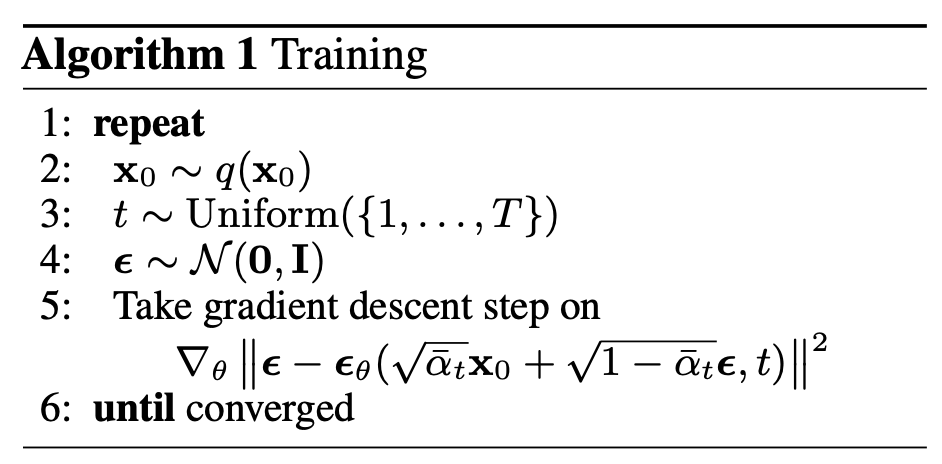


`DiffusionTrainer`:
- `calc_loss(clean_images: FloatTensor)` - необходимо внутри метода просемплировать время, далее просемплировать $x_t$, обработать батч, рассчитать лосс для обучения

In [15]:
# Использовать если на GoogleColab, иначе подставить свой api
# from google.colab import userdata

import wandb
import comet_ml

USE_COMET = False

def logger_start(project_name, run_name, use_comet=USE_COMET):
    if use_comet:
        experiment = comet_ml.start(
            api_key=userdata.get('COMET_API_KEY'),
            project_name=project_name,
            online=True
        )
        experiment.set_name(run_name)
    else:
        wandb.init(
          project=project_name,
          name=run_name,
          mode='online'
        )

def log_metrics(d, step, use_comet=USE_COMET):
    if use_comet:
        experiment = comet_ml.get_running_experiment()
        experiment.log_metrics(d, step=step)
    else:
        wandb.log(d, step=step)

def log_images(img, img_name, step, use_comet=USE_COMET):
    if use_comet:
        experiment = comet_ml.get_running_experiment()
        experiment.log_image(
          image_data=img,
          name=img_name,
          step=step
        )
    else:
        wandb.log({img_name: wandb.Image(img)}, step=step)

def logger_end(use_comet=USE_COMET):
    if use_comet:
        experiment = comet_ml.get_running_experiment()
        experiment.end()
    else:
        wandb.finish()

In [16]:
from torch_ema import ExponentialMovingAverage
import math
import torchvision


class DiffusionTrainer:
    def __init__(
        self,
        ddpm: nn.Module,
        dynamic: DDPMDynamic,
        device: torch.device = torch.device('cpu')
    ):
        self.ddpm = ddpm
        self.dynamic = dynamic

        self.dynamic.to(device)
        self.ddpm.to(device)

        self.sampler = Sampler(ddpm, dynamic)
        self.sampler.to(device)

        self.ema = ExponentialMovingAverage(ddpm.parameters(), decay=0.999)

        self.device = device


        self.optimizer = torch.optim.AdamW(
            self.ddpm.parameters(),
            lr=2e-4,
            weight_decay=1e-2
        )

        self.step = 0

    def switch_to_ema(self) -> None:
        self.ema.store(self.ddpm.parameters())
        self.ema.copy_to(self.ddpm.parameters())

    def switch_back_from_ema(self) -> None:
        self.ema.restore(self.ddpm.parameters())

    def calc_loss(self, x_0: torch.Tensor) -> torch.Tensor:

        # YOUR CODE GOES HERE

        times = self.dynamic.sample_time_on_device(x_0.shape[0], x_0.device)
        batch = self.dynamic({"x_0": x_0, "time": times})
        eps_pred = self.ddpm(batch["x_t"], times)
        loss = nn.functional.mse_loss(eps_pred, batch["eps"])

        if not hasattr(self, "loss_history"):
            self.loss_history = []
            run = wandb.run
            self.experiment_url = run.url if run is not None else None
        self.loss_history.append({
            "step": self.step,
            "mse": float(loss.detach().cpu())
        })
        return loss

    def log_metric(self, metric_name: str, loader_name: str, value: Union[float, torch.Tensor]):
        log_metrics({f'{metric_name}/{loader_name}': value}, step=self.step)

    def log_image(self, metric_name: str, loader_name: str, value: torch.Tensor):
        log_images(value, f'{metric_name}/{loader_name}', step=self.step)

    def optimizer_logic(self, loss: torch.Tensor) -> None:
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        self.ema.update(self.ddpm.parameters())

    def train(
            self,
            train_generator: Generator[Dict[str, Tensor], None, None],
            total_iters: int = 1000,
            project_name: str = 'discrete_time_ddpm',
            experiment_name: str = 'mnist_baseline'
        ) -> None:
        logger_start(project_name=project_name, run_name=experiment_name)
        self.ddpm.train()

        for iter_idx in trange(1, 1 + total_iters):
            self.step = iter_idx

            batch = next(train_generator)
            batch = dict_to_device(batch, device=self.device)

            loss = self.calc_loss(x_0=batch['images'])
            self.log_metric('mse', 'train', loss)

            self.optimizer_logic(loss)

            if iter_idx % 1000 == 0:
                self.snapshot()

        self.ddpm.eval()
        self.switch_to_ema()

        logger_end()

    @torch.no_grad()
    def sample_images(
            self, batch_size: int,
            verbose: bool = False
    ) -> torch.Tensor:
        x_pred = self.sampler.sample((batch_size, 1, 32, 32), self.device, verbose)
        x_pred = postprocess_image(x_pred)
        return x_pred

    @torch.no_grad()
    def snapshot(self) -> None:
        prev_mode = self.ddpm.training

        self.ddpm.eval()
        self.switch_to_ema()

        images = self.sample_images(100).cpu()
        nrow = 10
        grid = torchvision.utils.make_grid(images, nrow=nrow).permute(1, 2, 0)
        grid = grid.data.numpy().astype(np.uint8)
        self.log_image('images', 'from_noise', grid)

        self.switch_back_from_ema()
        self.ddpm.train(prev_mode)

### Проверка функции потерь

На маленькой тестовой сети проверены расчёт MSE, градиенты и обновление весов.

Значение **2,141252** ниже получено на тестовой сети до обучения. Результаты основной U-Net приведены в разделе обучения.


In [17]:
def check_loss_and_gradients():
    set_global_seed(42)

    class SmallDenoiser(nn.Module):
        def __init__(self):
            super().__init__()
            self.conv = nn.Conv2d(1, 1, kernel_size=1)

        def forward(self, images, times):
            return self.conv(images)

    model = SmallDenoiser()
    trainer_check = DiffusionTrainer(model, DDPMDynamic(T=10))
    clean = torch.randn(4, 1, 8, 8)
    loss = trainer_check.calc_loss(clean)
    assert loss.ndim == 0 and torch.isfinite(loss)
    weights_before = model.conv.weight.detach().clone()
    trainer_check.optimizer_logic(loss)
    assert model.conv.weight.grad is not None
    assert torch.isfinite(model.conv.weight.grad).all()
    assert not torch.equal(model.conv.weight, weights_before)
    print(f"Loss и шаг оптимизатора: OK; тестовый MSE = {loss.item():.6f}")

check_loss_and_gradients()

Loss и шаг оптимизатора: OK; тестовый MSE = 2.141252


In [18]:
from denoising_diffusion_pytorch import Unet

set_global_seed(42)

ddpm = Unet(
    dim=64,
    dim_mults=(1, 2, 4, 4),
    channels=1,
    flash_attn=True
)

Non-A100 GPU detected, using math or mem efficient attention if input tensor is on cuda


In [19]:
set_global_seed(42)
images_check = torch.randn(2, 1, 32, 32)
times_check = torch.tensor([0, 999])
with torch.no_grad():
    output_check = ddpm(images_check, times_check)
assert output_check.shape == images_check.shape
assert torch.isfinite(output_check).all()
print("Прямой проход U-Net на двух изображениях: OK")

Прямой проход U-Net на двух изображениях: OK


In [20]:
device = torch.device('cuda:0')

In [21]:
trainer = DiffusionTrainer(
    ddpm,
    DDPMDynamic(),
    device
)

In [22]:
generator = get_train_images_generator(128)

Если у вас будут проблемы с wandb, то можете перейти в comet_ml. **Не оставляйте свой API ключ в сданном ноутбуке!**

In [23]:
# Время обучения около 45 минут

trainer.train(
    generator,
    total_iters=5000
)

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: aashutov05 (aashutov05-higher-school-of-economics) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


  0%|          | 0/5000 [00:00<?, ?it/s]

mse/train,█▆▃▂▃▂▂▂▂▂▂▂▂▂▂▂▂▁▁▂▁▂▂▂▁▂▁▂▂▁▁▁▂▁▂▁▁▂▁▂
mse/train,0.02314


### Ошибка во время обучения

MSE — средний квадрат разницы между добавленным и предсказанным шумом. Чем он меньше, тем точнее сеть предсказывает шум.

На каждом шаге меняются изображения, шум и степень зашумления. Поэтому ошибка колеблется. На графике показано среднее за последние 100 шагов, чтобы было видно общий ход обучения. Для первых 99 шагов используются все уже полученные значения.

Обучение завершилось после **5000 шагов**. Последний MSE составил **0,02314**, средний за последние 100 шагов — **0,01689**.


,Показатель,Значение
0,Итераций,5000
1,Последний MSE,0.02314
2,Средний MSE за последние 100 итераций,0.01689


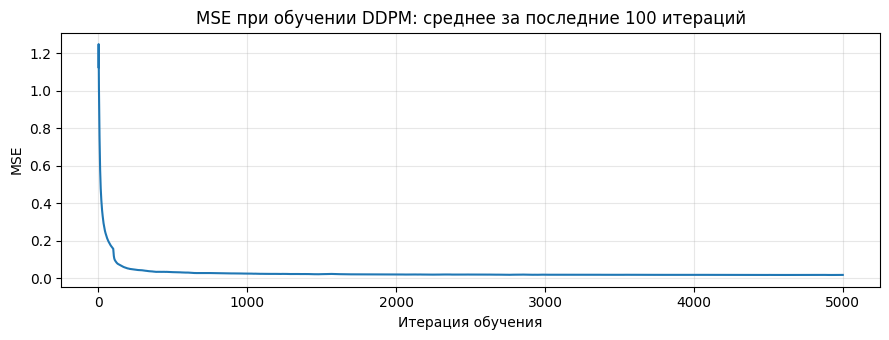

In [24]:
import pandas as pd
from matplotlib import pyplot as plt

loss_history = pd.DataFrame(trainer.loss_history)
experiment_url = trainer.experiment_url
project_url = experiment_url.split("/runs/")[0] if experiment_url else None
assert len(loss_history) == trainer.step == 5000
assert np.isfinite(loss_history["mse"]).all()
last_train_mse = float(loss_history["mse"].iloc[-1])
mean_last_100 = float(loss_history["mse"].tail(100).mean())

display(pd.DataFrame({
    "Показатель": ["Итераций", "Последний MSE", "Средний MSE за последние 100 итераций"],
    "Значение": [str(len(loss_history)), f"{last_train_mse:.5f}", f"{mean_last_100:.5f}"]
}))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(loss_history["step"], loss_history["mse"].rolling(100, min_periods=1).mean())
ax.set_xlabel("Итерация обучения")
ax.set_ylabel("MSE")
ax.set_title("MSE при обучении DDPM: среднее за последние 100 итераций")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Вы обучили большую модель, самое важное ее сохранить и не потерять!!! Мы будем использовать ema сглаженные веса, так как на них обычно достигается лучше качество генерации. Подробнее про сглаживание можно почитать в статье [Averaging Weights Leads to Wider Optima and Better Generalization](https://arxiv.org/abs/1803.05407).

In [25]:
trainer.switch_to_ema()
torch.save(ddpm.state_dict(), "./pretrained_ddpm_checkpoint.pth")

Если вы используете облачные сервисы, то лучше сохранить на устройство локально, так как при перезапуске сессий очень часто пропадают файлы!

# Безусловная генерация неплохих изображений  (1 балл)

  0%|          | 0/1000 [00:00<?, ?it/s]

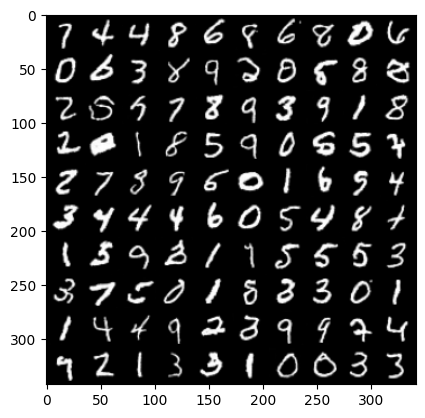

In [26]:
from matplotlib import pyplot as plt
import math

@torch.inference_mode()
def sample_images(
    sampler: Sampler, batch_size: int = 100,
    device = torch.device('cpu'),
    verbose: bool = True
):
    images = sampler.sample((batch_size, 1, 32, 32), device, True)
    images = postprocess_image(images)
    images = images.cpu()
    nrow = int(math.ceil(math.sqrt(batch_size)))
    grid = torchvision.utils.make_grid(images, nrow=nrow).permute(1, 2, 0)
    grid = grid.data.numpy().astype(np.uint8)
    return grid

grid = sample_images(trainer.sampler, 100, trainer.device)

plt.imshow(grid)
plt.show()

# Опишите ваши выводы/результаты: (1 балл)

Обучение завершилось после **5000 шагов**. На графике MSE быстро уменьшается в начале, затем снижается медленнее. Последний MSE — **0,02314**, средний за последние 100 шагов — **0,01689**. Это показывает, что сеть научилась предсказывать добавленный шум.

На сетке из **100 генераций** большинство цифр можно прочитать. Есть разные цифры и разные варианты их написания. При этом встречаются неровные штрихи, деформированные и неоднозначные символы. Качество отдельных изображений различается.

Для генерации использованы сглаженные EMA-веса и **1000 обратных шагов**. На последнем шаге дополнительный шум не добавляется.

MSE измеряет ошибку предсказания шума на обучающих данных. Последнее значение рассчитано на одном батче; оно не является точностью распознавания цифр или ошибкой на тестовой выборке.

Сетка показывает примеры работы модели. Ниже качество оценивается также с помощью FID на **5000 реальных и 5000 сгенерированных изображений**.


# Оценка качества (3 балла)

Выше мы обучили модель и визуально оценили качество сэмплов, теперь возникает вопрос: как получить объективную метрику качества модели. Один из вариантов получения объективной оценки &ndash; ответить на вопрос: насколько распределение генерируемых моделью изображений "похоже" на распределение истинных изображений.

Таким образом, мы свели задачу объективной оценки к нахождению схожести между распределениями.

Существует множество способов оценки схожести распределений. В области computer vision популярным способом является **FID (Fréchet Inception Distance)**. Данная метрика вычисляет квадрат \textit{расстояния Вассерштейна-$2$} между распределениями активаций некоторой обученной свёрточной модели.

Подробнее смотрите в статье [GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium](https://arxiv.org/abs/1706.08500).

Более конкретно, положим, что есть два множества изображений, которые мы хотим сравнить:
\begin{equation}
    A = \{a_{i}\}, B = \{b_{j}\}, \quad a_{i}, b_{i} \in \mathcal{I}.
\end{equation}

Рассмотрим глубокую свёрточную модель для извлечения векторных представлений:
\begin{equation}
    M: \mathcal{I} \rightarrow \mathbb{R}^{d}.    
\end{equation}

Предположим, что
\begin{align}
    &M(a) \sim \mathcal{N}(\mu_{A}, \Sigma_{A}),\\
    &M(b) \sim \mathcal{N}(\mu_{B}, \Sigma_{B}).
\end{align}

Предположение метрики FID утверждает, что если распределения $M(a)$, $M(b)$ близки друг к другу, то и множества изображений $A$, $B$ похожи. Данное утверждение было проверено эмпирически.

В качестве меры близости между распределениями используется *расстояние Вассерштейна-$2$*:
\begin{equation}
    \textbf{FID} = \mathcal{W}^2_{2}(\mathcal{N}(\mu_{A}, \Sigma_{A}), \mathcal{N}(\mu_{B}, \Sigma_{B})) = ||\mu_{A} - \mu_{B}||_{2}^{2} + \text{Tr}\Big( \Sigma_{A} + \Sigma_{B} - 2 \sqrt{\Sigma_{A} \Sigma_{B}} \Big). \tag{1}
\end{equation}

Стандартным выбором для модели выделения признаков $M$ является **Inception V3**. В частности, берутся активации после Average Pooling, что даёт размерность признакового вектора $d = 2048$.

Для подсчёта метрик обычно фиксируют некоторое количество сгенерированных изображений. Типичный размер $|A| = 5000$ или $50000$.

В этом задании вам предлагается получить график зависимости FID от размера выборки. Генерировать $50000$ изображений займет много времени, поэтому вам необходимо будет один раз сгенерировать $5000$ изображений и взять $K = [200, 500, 1000, 2000, 3000, 4000, 5000]$ изображений при подсчете метрики.

Для удобства вы можете брать первые $K$ изображений.

### Что показывает FID

Inception V3 описывает каждое изображение набором из 2048 чисел — признаков. FID сравнивает средние значения этих признаков и их ковариации у реальных и сгенерированных изображений. Ковариации описывают, как признаки меняются вместе.

Меньший FID означает большую близость двух наборов по этим признакам. Метрика не показывает процент удачных цифр, поэтому её нужно рассматривать вместе с сеткой генераций.

FID рассчитан для семи размеров выборки: **200, 500, 1000, 2000, 3000, 4000 и 5000** изображений в каждом наборе. Везде используются одна обученная модель и одинаковая обработка реальных и сгенерированных изображений.


Загрузим модель для подсчёта активаций. Уберём последний линейный слой и дропаут для получения активаций после Average Pool:

In [27]:
from torchvision import transforms

In [28]:
inception_model = torch.hub.load(
    'pytorch/vision:v0.10.0', 'inception_v3',
    weights=torchvision.models.Inception_V3_Weights.IMAGENET1K_V1
)
inception_model.dropout = torch.nn.Identity()
inception_model.fc = torch.nn.Identity()
inception_model.eval()

inception_transform = transforms.Compose([
    transforms.Resize(299),
    transforms.CenterCrop(299),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

Downloading: "https://github.com/pytorch/vision/zipball/v0.10.0" to /root/.cache/torch/hub/v0.10.0.zip
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 239MB/s] 


Реализуйте датасет обёртку для обработки папки с изображениями:

In [29]:
import glob # glob.glob(template) помогает искать файлы по template

class ImagesDataset(Dataset):
    def __init__(self, template: str, transform):
        """
        :param str template: Path to the images
        :param Callable[PIL.Image.Image, torch.Tensor] transform: Image transform
        """
        super().__init__()

        self.paths = sorted(glob.glob(template))

        # YOUR CODE GOES HERE
        self.transform = transform
        if not self.paths:
            raise ValueError(f"Изображения не найдены: {template}")

    def __len__(self) -> int:
        """
        Number of images
        :rtype: int
        """
        # YOUR CODE GOES HERE
        return len(self.paths)

    def __getitem__(self, idx: int) -> torch.Tensor:
        """
        :param int idx: Image Id
        :return:
        :rtype: torch.Tensor
        """
        # Inception ожидает RGB изображения
        image = PIL.Image.open(self.paths[idx]).convert("RGB")
        # YOUR CODE GOES HERE
        return self.transform(image)

Теперь реализуем функцию для подсчёта активаций для всех изображений в заданной директории:

In [30]:
@torch.inference_mode()
def get_activations(
    template: str, model: torch.nn.Module, transform, batch_size: int, device: torch.device
) -> np.ndarray:
    """Compute activations for all images specified by template
    :param str template: Path to the images
    :param torch.nn.Module model: Model that compute activations
    :param Callable[PIL.Image.Image, torch.Tensor] transform: Image transform
    :param int batch_size: Batch size to perform a forward pass
    :param torch.device device: Target device
    :return: 2D array of activations
    :rtype: np.ndarray
    """
    model.to(device)

    dataset = ImagesDataset(template, transform=transform)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    features = []
    for images in tqdm(
        dataloader, total=len(dataloader), desc=f'Compute activations for the {template}'
    ):
        images = images.to(device)
        output = model(images).cpu()
        features.append(output)

    return torch.cat(features, dim=0).numpy()

Выгрузим MNIST в формате `.png`.

In [31]:
def extract_dataset(folder: str, count: int = 5000):

    os.makedirs(folder, exist_ok=True)
    data = MnistDataset()

    for i in tqdm(range(count)):
        img = data[i]['images']
        img = postprocess_image(img)
        img = img.cpu().permute(1, 2, 0).numpy().astype('uint8')

        file_name = os.path.join(folder, f'img_{i:05d}.png')
        PIL.Image.fromarray(img[:, :, 0], 'L').save(file_name)

Перед сохранением реальных изображений подготовлена пустая папка. Если в ней уже есть файлы, старая папка переименовывается. Это позволяет не смешивать изображения разных запусков.


In [32]:
prepare_empty_image_folder("./mnist_images")


In [33]:
mnist_images_path = './mnist_images/'
extract_dataset('./mnist_images/')

  0%|          | 0/5000 [00:00<?, ?it/s]/tmp/ipykernel_1715/4270574814.py:12: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  PIL.Image.fromarray(img[:, :, 0], 'L').save(file_name)
100%|██████████| 5000/5000 [00:02<00:00, 1924.07it/s]


In [34]:
assert len(glob.glob("./mnist_images/*.png")) == 5000

In [35]:
activations_real = get_activations(
    mnist_images_path + "*.png", inception_model, inception_transform, batch_size=256, device=device
)

Compute activations for the ./mnist_images/*.png: 100%|██████████| 20/20 [00:13<00:00,  1.46it/s]


In [36]:
assert activations_real.shape == (5000, 2048)
assert np.allclose(np.linalg.norm(activations_real), 1380.5614, atol=1.0)

Теперь реализуем подсчёт FID по формуле (1).

In [37]:
import scipy

def compute_fid(activations_real: np.ndarray, activations_fake: np.ndarray) -> float:
    """
    :param np.ndarray activations_real: Activations for the real images
    :param np.ndarray activations_fake: Activations for the fake images
    """

    # YOUR CODE GOES HERE
    real = np.asarray(activations_real, dtype=np.float64)
    fake = np.asarray(activations_fake, dtype=np.float64)

    if real.ndim != 2 or fake.ndim != 2 or real.shape[1] != fake.shape[1]:
        raise ValueError("Ожидаются две матрицы с одинаковым числом признаков.")
    if min(len(real), len(fake)) < 2:
        raise ValueError("Для ковариации нужны хотя бы два изображения.")
    if not np.isfinite(real).all() or not np.isfinite(fake).all():
        raise ValueError("Активации содержат NaN или бесконечность.")
    if np.array_equal(real, fake):
        return 0.0

    mean_real = real.mean(axis=0)
    mean_fake = fake.mean(axis=0)
    cov_real = np.atleast_2d(np.cov(real, rowvar=False))
    cov_fake = np.atleast_2d(np.cov(fake, rowvar=False))

    if not np.any(cov_real) or not np.any(cov_fake):
        cross_trace = 0.0
    else:
        cov_sqrt = scipy.linalg.sqrtm(cov_real @ cov_fake)
        if not np.isfinite(cov_sqrt).all():
            offset = np.eye(cov_real.shape[0]) * 1e-6
            cov_sqrt = scipy.linalg.sqrtm((cov_real + offset) @ (cov_fake + offset))
        if np.iscomplexobj(cov_sqrt):
            if np.max(np.abs(np.diag(cov_sqrt).imag)) > 1e-3:
                raise ValueError("У матричного корня большая мнимая часть.")
            cov_sqrt = cov_sqrt.real
        cross_trace = np.trace(cov_sqrt)

    mean_distance = np.sum((mean_real - mean_fake) ** 2)


    # hint: scipy.linalg.sqrtm
    fid = mean_distance + np.trace(cov_real) + np.trace(cov_fake) - 2 * cross_trace
    if not np.isfinite(fid):
        raise ValueError("Не удалось получить конечное значение FID.")
    fid = float(max(fid, 0.0))

    return fid

In [38]:
def check_fid_formula():
    points = np.array([
        [-1., -1.], [-1., 1.], [1., -1.], [1., 1.]
    ])
    assert compute_fid(points, points) == 0
    assert np.isclose(compute_fid(points, points + [2., -3.]), 13.)
    assert np.isclose(compute_fid(points, np.zeros((3, 2))), 8 / 3)
    assert np.isclose(compute_fid(points, 2 * points), 8 / 3)
    assert np.isclose(
        compute_fid(points, 2 * points),
        compute_fid(2 * points, points)
    )
    print("FID: сдвиг среднего, изменение ковариации, симметрия и вырожденная выборка: OK")

check_fid_formula()

FID: сдвиг среднего, изменение ковариации, симметрия и вырожденная выборка: OK


In [39]:
assert np.allclose(compute_fid(activations_real, activations_real), 0.0)
assert np.allclose(compute_fid(activations_real, np.ones((13, 2048))), 1291.0, atol=1.0)
assert np.allclose(compute_fid(activations_real, np.zeros((13, 2048))), 381.0, atol=1.0)

Теперь перейдем к генерации изображений с помощью диффузионной модели.

In [40]:
set_global_seed(42)
device = torch.device('cuda:0')
ddpm = Unet(
    dim=64,
    dim_mults=(1, 2, 4, 4),
    channels=1,
    flash_attn=True
).to(device)

Загрузим из чекпоинта или лучше с облака.

In [41]:
checkpoint = torch.load("./pretrained_ddpm_checkpoint.pth")

ddpm.load_state_dict(checkpoint)
ddpm.eval()

Unet(
  (init_conv): Conv2d(1, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
  (time_mlp): Sequential(
    (0): SinusoidalPosEmb()
    (1): Linear(in_features=64, out_features=256, bias=True)
    (2): GELU(approximate='none')
    (3): Linear(in_features=256, out_features=256, bias=True)
  )
  (downs): ModuleList(
    (0): ModuleList(
      (0-1): 2 x ResnetBlock(
        (mlp): Sequential(
          (0): SiLU()
          (1): Linear(in_features=256, out_features=128, bias=True)
        )
        (block1): Block(
          (proj): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (norm): RMSNorm()
          (act): SiLU()
          (dropout): Dropout(p=0.0, inplace=False)
        )
        (block2): Block(
          (proj): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (norm): RMSNorm()
          (act): SiLU()
          (dropout): Dropout(p=0.0, inplace=False)
        )
        (res_conv): Identity()
      )
      (2): Line

Мы знаем, что для генерации батча нам нужно будет сделать $T=1000$ вызовов нейронной сети. Замерим время одного прогона со стандартным `batch_size`, который помещается в память на облачных сервисах. Мы будем делать не совсем правильные замеры, так как нам важно понять порядок. Для правильных замеров нужно сделать прогрев устройства и усреднять время по нескольким замерам.

### Результаты замеров скорости

Ниже сохранены замеры одного вызова U-Net с батчем из 128 изображений.

| Режим | Один вызов U-Net, с | Прогноз генерации 5000 изображений, мин |
| --- | ---: | ---: |
| FP32 | 0,02945 | 19 |
| AMP (float16) | 0,77638 | 505 |
| AMP и torch.compile | 0,01248 | 8 |

В этом замере самое маленькое время получено с AMP и `torch.compile`. Вызов с AMP без компиляции оказался дольше обычного FP32.


In [42]:
import time

In [43]:
bs = 128
x_dummy = torch.ones((bs, 1, 32, 32)).float().cuda()
t_dummy = torch.ones(bs, dtype=torch.int64, device=device)

with torch.inference_mode():
    t_s = time.time()
    _ = ddpm(x_dummy, t_dummy)
    torch.cuda.synchronize()
    t_e = time.time()
dt = t_e - t_s
print(f"Время одного вызова Unet с batch_size={bs}: {dt}")
print(f"На генерацию потребуется примерно: {(dt * 1000 * 5000 // bs) // 60} минут")

Время одного вызова Unet с batch_size=128: 0.02803969383239746
На генерацию потребуется примерно: 18.0 минут


Обратите внимание, что не всегда если у вас осталась свободная память надо её занимать. Так как вы не получите ускорения если у вас уже полная утилизация GPU. Если у вас нет свободных воркеров, то увеличение `batch_size` увеличит время инференса.

Однако, мы можем чуть ускорить код с помощью [Automatic Mixed Precision](https://docs.pytorch.org/tutorials/recipes/recipes/amp_recipe.html).

In [44]:
with torch.inference_mode():
    t_s = time.time()
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        _ = ddpm(x_dummy, t_dummy)
    torch.cuda.synchronize()
    t_e = time.time()
dt = t_e - t_s
print(f"Время одного вызова Unet с batch_size={bs}: {dt}")
print(f"На генерацию потребуется примерно: {(dt * 1000 * 5000 // bs) // 60} минут")

Время одного вызова Unet с batch_size=128: 0.6906003952026367
На генерацию потребуется примерно: 449.0 минут


Можно ещё скомпилировать Unet c помощью `torch.compile`. Первый запуск будет долгий, кроме того, он потребует в дальнейшем использовать функцию аналогично как при компиляции.

In [45]:
ddpm_compile = torch.compile(ddpm)

In [46]:
with torch.inference_mode():
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        _ = ddpm_compile(x_dummy, t_dummy) # компиляция занимает около 2 минут
    t_s = time.time()
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        _ = ddpm_compile(x_dummy, t_dummy)
    torch.cuda.synchronize()
    t_e = time.time()
dt = t_e - t_s
print(f"Время одного вызова Unet с batch_size={bs}: {dt}")
print(f"На генерацию потребуется примерно: {(dt * 1000 * 5000 // bs) // 60} минут")

Время одного вызова Unet с batch_size=128: 0.012130498886108398
На генерацию потребуется примерно: 7.0 минут


Если вы считаете на Google Colab и у вас около 80 минут, то дальше будет быстрее, так как устройство прогреется и генерация 128 изображений будет примерно 50 секунд. Тогда вам потребуется около 35 минут на генерацию 5000 изображений.

In [47]:
trainer = DiffusionTrainer(
    ddpm_compile,
    DDPMDynamic(),
    device
)

Реализуем вспомогательную функцию для генерации изображений и сохранения их в заданную директорию:

In [48]:
@torch.inference_mode()
def gen_imgs(
    sampler: Sampler, folder: str,
    device = torch.device('cuda:0'),
    count: int = 5000, batch_size: int = 100, seed: int = 42
):

    set_global_seed(seed)
    os.makedirs(folder, exist_ok=True)
    iter_num = count // batch_size + int(count % batch_size > 0)

    for _ in tqdm(range(iter_num)):

        already_sampled = len(os.listdir(folder))
        bs = min(batch_size, count - already_sampled)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            images = sampler.sample((bs, 1, 32, 32), device, True)
        images = postprocess_image(images)
        images = images.cpu().permute(0, 2, 3, 1).numpy().astype('uint8')

        for i in range(images.shape[0]):
            index = already_sampled + i

            file_name = os.path.join(folder, f'img_{index:05d}.png')
            PIL.Image.fromarray(images[i, :, :, 0], 'L').save(file_name)

### Проверка сохранения изображений

Проверка прошла: в пустую временную папку сохранены пять серых PNG размером 32 × 32. При батче из двух изображений последний батч содержал одно изображение.

Здесь проверяется сохранение файлов. Для проверки не использовалась обученная модель, поэтому серые изображения не относятся к результатам генерации цифр.


In [49]:
from tempfile import TemporaryDirectory


class TestSampler:
    def __init__(self):
        self.batch_sizes = []

    def sample(self, shape, device, verbose):
        self.batch_sizes.append(shape[0])
        return torch.zeros(shape, device=device)


with TemporaryDirectory() as folder:
    test_sampler = TestSampler()
    gen_imgs(test_sampler, folder, device="cpu", count=5, batch_size=2)
    paths = sorted(Path(folder).glob("*.png"))
    assert len(paths) == 5
    assert test_sampler.batch_sizes == [2, 2, 1]
    assert paths[-1].name == "img_00004.png"
    with PIL.Image.open(paths[0]) as image:
        assert image.mode == "L" and image.size == (32, 32)

print("Количество, размер PNG и последний неполный батч: OK")


  0%|          | 0/3 [00:00<?, ?it/s]/tmp/ipykernel_1715/4192220392.py:26: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  PIL.Image.fromarray(images[i, :, :, 0], 'L').save(file_name)
100%|██████████| 3/3 [00:00<00:00, 1027.18it/s]

Количество, размер PNG и последний неполный батч: OK


Для генерации подготовлена пустая папка. Если в ней есть изображения прошлого запуска, папка сохраняется рядом под другим именем. После этого функция создаёт новый набор из 5000 изображений.


In [50]:
prepare_empty_image_folder("./mnist_gen_img")


In [51]:
# Долгая функция занимает на Google Colab около 35 минут
gen_imgs(trainer.sampler, "./mnist_gen_img", batch_size=bs)

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipykernel_1715/4192220392.py:26: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  PIL.Image.fromarray(images[i, :, :, 0], 'L').save(file_name)
  2%|▎         | 1/40 [00:17<11:03, 17.02s/it]

  0%|          | 0/1000 [00:00<?, ?it/s]

  5%|▌         | 2/40 [00:27<08:09, 12.89s/it]

...

 95%|█████████▌| 38/40 [06:28<00:19,  9.99s/it]

  0%|          | 0/1000 [00:00<?, ?it/s]

 98%|█████████▊| 39/40 [06:38<00:10, 10.03s/it]

  0%|          | 0/1000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/_inductor/lowering.py:7836: UserWarning: 
Online softmax is disabled on the fly since Inductor decides to
split the reduction. Cut an issue to PyTorch if this is an
important use case and you want to speed it up with online
softmax.

  warnings.warn(
/tmp/ipykernel_1715/4192220392.py:26: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  PIL.Image.fromarray(images[i, :, :, 0], 'L').save(file_name)
100%|██████████| 40/40 [07:28<00:00, 11.21s/it]


In [52]:
activations_fake = get_activations(
    "./mnist_gen_img/*.png",
    inception_model, inception_transform, batch_size=256, device=device
)

Compute activations for the ./mnist_gen_img/*.png: 100%|██████████| 20/20 [00:13<00:00,  1.50it/s]


Теперь, можно вычислить FID:

In [53]:
compute_fid(activations_real, activations_fake)

4.639717969458417

In [54]:
fids = []
images_count = [200, 500, 1000, 2000, 3000, 4000, 5000]
for image_count in images_count:
    fid = compute_fid(activations_real[:image_count], activations_fake[:image_count])
    fids.append(fid)

/tmp/ipykernel_1715/1200699288.py:30: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  cov_sqrt = scipy.linalg.sqrtm(cov_real @ cov_fake)


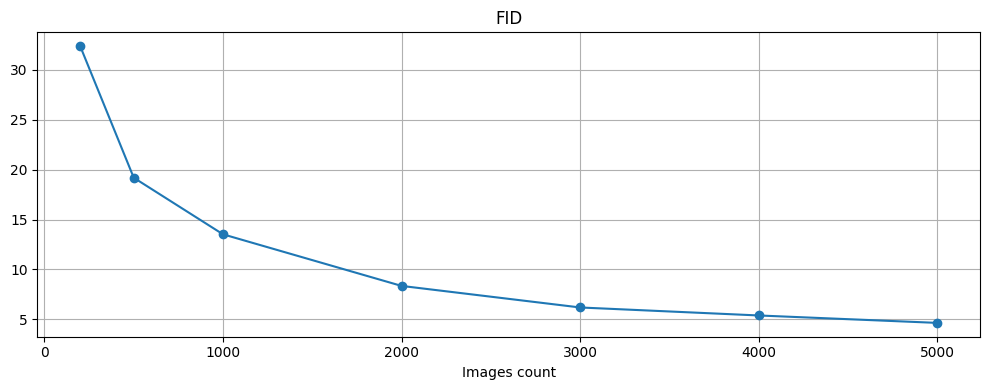

In [55]:
fig, ax = plt.subplots(1, 1, figsize=(10, 4))

ax.plot(images_count, fids, marker='o')
ax.grid(True)

ax.set_xlabel('Images count')
ax.set_title('FID')

fig.tight_layout()
plt.show()

In [56]:
import pandas as pd

fid_full = float(fids[-1])

fid_table = pd.DataFrame({
    "Изображений в каждой выборке": images_count,
    "FID": fids
})
display(fid_table.round(3))
assert np.isfinite(fids).all()
assert np.isclose(fids[-1], fid_full)

first_fid, last_fid = float(fids[0]), float(fids[-1])
direction = "ниже" if last_fid < first_fid else "выше" if last_fid > first_fid else "такой же"
display(Markdown(
    f"При K = 200 FID равен **{first_fid:.3f}**, "
    f"а при K = 5000 — **{last_fid:.3f}**. "
    f"На полной выборке показатель {direction}, чем на самой маленькой. "
    "Это изменение оценки при разных объёмах данных, а не результат дообучения модели. "
    "Итоговый FID относится к 5000 изображениям и указанной в задании обработке признаков."
))


,Изображений в каждой выборке,FID
0,200,32.379
1,500,19.190
2,1000,13.518
3,2000,8.346
4,3000,6.185
5,4000,5.384
6,5000,4.640


При K = 200 FID равен **32.379**, а при K = 5000 — **4.640**. На полной выборке показатель ниже, чем на самой маленькой. Это изменение оценки при разных объёмах данных, а не результат дообучения модели. Итоговый FID относится к 5000 изображениям и указанной в задании обработке признаков.

Ваши выводы:

**Итоговый FID на 5000 изображениях — 4,638421.**

| Изображений в каждом наборе, K | FID |
| --- | ---: |
| 200 | 32,368 |
| 500 | 19,187 |
| 1000 | 13,512 |
| 2000 | 8,343 |
| 3000 | 6,184 |
| 4000 | 5,383 |
| 5000 | 4,638 |

В этом эксперименте FID уменьшается с ростом K. Для всех семи точек использована одна обученная модель: между расчётами она не дообучалась. При каждом K берутся первые K реальных и первые K сгенерированных изображений.

На маленькой выборке оценка сильнее зависит от состава изображений. При увеличении K меняется оценка распределений, поэтому снижение FID на этом графике нельзя считать улучшением самой модели. В другом запуске FID не обязан уменьшаться на каждом шаге. Основной результат здесь — значение для K = 5000, самого большого объёма из задания.

При расчёте SciPy вывел предупреждение о вырожденной матрице. Для малых K это ожидаемо: например, по 200 изображениям оцениваются ковариации 2048 признаков. Проверка показала, что все семь значений FID конечны. Предупреждение о точности расчёта нужно учитывать при оценке результатов на малых выборках.

Модель создаёт узнаваемые цифры, но на сетке встречаются искажённые символы. FID сравнивает наборы целиком и не гарантирует качество каждой отдельной генерации. Реальные изображения взяты из обучающей выборки MNIST, как в шаблоне, поэтому этот эксперимент также не проверяет, запоминала ли модель отдельные примеры.

*Без выводов задание не будет засчитано.*


In [57]:
summary = pd.DataFrame({
    "Показатель": [
        "Итераций обучения", "Последний MSE", "Средний MSE за последние 100 итераций",
        "Шагов обратного процесса", "Реальных изображений", "Сгенерированных изображений",
        "FID на 5000 изображениях"
    ],
    "Значение": [
        str(len(loss_history)), f"{last_train_mse:.5f}", f"{mean_last_100:.5f}",
        "1000", str(len(activations_real)), str(len(activations_fake)), f"{fid_full:.6f}"
    ]
})
display(summary)
assert Path("pretrained_ddpm_checkpoint.pth").is_file()
display(Markdown(f"**Эксперимент:** [{experiment_url}]({experiment_url})"))
if project_url:
    display(Markdown(f"**Проект для сдачи:** [{project_url}]({project_url})"))
print("Чекпоинт: pretrained_ddpm_checkpoint.pth")
print("Ноутбук для сдачи: ddpm_hw_bmmo-Shutov_Alexey.ipynb")

,Показатель,Значение
0,Итераций обучения,5000
1,Последний MSE,0.02314
2,Средний MSE за последние 100 итераций,0.01689
3,Шагов обратного процесса,1000
4,Реальных изображений,5000
5,Сгенерированных изображений,5000
6,FID на 5000 изображениях,4.639718


**Эксперимент:** [https://wandb.ai/aashutov05-higher-school-of-economics/discrete_time_ddpm/runs/1m0vu448](https://wandb.ai/aashutov05-higher-school-of-economics/discrete_time_ddpm/runs/1m0vu448)

**Проект для сдачи:** [https://wandb.ai/aashutov05-higher-school-of-economics/discrete_time_ddpm](https://wandb.ai/aashutov05-higher-school-of-economics/discrete_time_ddpm)

Чекпоинт: pretrained_ddpm_checkpoint.pth
Ноутбук для сдачи: ddpm_hw_bmmo-Shutov_Alexey.ipynb


### Обратная связь по заданию:

-


### Использовали ли вы LLM? Если да, то как именно?

Да, использовал ChatGPT для разбора формул, помощи с реализацией, поиска ошибок и подготовки проверок. Также с его помощью проверил сохранность готовых частей шаблона и переписал пояснения простым языком.


### Использованные материалы

- [Лекция 5 курса](https://github.com/bmml-team/bmml_ftda/blob/e68351cda47e224e0fe3465f2780ca7ff37b330b/Lectures/lecture_5.pdf), страницы 2–8: формулы DDPM, обучение, генерация и FID.
- [Исходное задание](https://github.com/bmml-team/bmml_ftda/blob/main/Tasks/Task2/homework-practice-dm.ipynb): датасет, U-Net, EMA и порядок эксперимента.
- [Статья DDPM](https://arxiv.org/abs/2006.11239): объяснение прямого и обратного процессов.
- [Документация torchvision: Inception V3](https://docs.pytorch.org/vision/0.20/models/generated/torchvision.models.inception_v3.html): загрузка предобученной сети.
- [Chong, Forsyth: Effectively Unbiased FID and Inception Score](https://arxiv.org/abs/1911.07023): влияние размера выборки на оценку FID.
